# Name:-Taha khan
Roll No:-33
Section:-C
Batch:-C3

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [7]:
df=pd.read_csv('seeds.csv')

In [8]:
df=df.dropna(axis=1,how="all")

In [9]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

Basic EDA

In [10]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [11]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [12]:
df.shape

(210, 8)

In [13]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='str')

In [14]:
df.dtypes

Area                       float64
Perimeter                  float64
Compactness                float64
Length of kernel           float64
Width of kernel            float64
Asymmetry coefficient      float64
Length of kernel groove    float64
Class (1, 2, 3)              int64
dtype: object

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [16]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [17]:
df.isnull().sum()

Area                       0
Perimeter                  0
Compactness                0
Length of kernel           0
Width of kernel            0
Asymmetry coefficient      0
Length of kernel groove    0
Class (1, 2, 3)            0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

Graphs and plots

Algorithm

In [19]:
X = df.drop('Class (1, 2, 3)',axis=1)
y_original=df['Class (1, 2, 3)']

print("Input Shape",X.shape)
print("Target Shape",y_original.shape)

Input Shape (210, 7)
Target Shape (210,)


In [20]:
y = y_original-1

print("Original Classes:")
print(sorted(y_original.unique()))
print("\n ANN encoded classes:")
print(sorted(y.unique()))

Original Classes:
[np.int64(1), np.int64(2), np.int64(3)]

 ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Training Sample:", X_train.shape)
print("Testing Sample:", X_test.shape)

Training Sample: (168, 7)
Testing Sample: (42, 7)


In [22]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [23]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [24]:
print("First 5 scaled training samples:")
print(X_train[:5])

First 5 scaled training samples:
[[-1.17682401 -1.1750583  -1.02169157 -1.02785725 -1.35751947  1.43188942
  -0.82441016]
 [-0.87298429 -1.06714618  0.86676795 -1.26492983 -0.59897345 -0.3056117
  -1.63150367]
 [-0.12719589  0.01968295 -0.66917913  0.25096694 -0.40933695 -1.4432301
   0.1615857 ]
 [-1.29421662 -1.37546651 -0.66498255 -1.41310019 -1.26136575  1.7668294
  -0.72886004]
 [-0.58295547 -0.70486981  0.69890488 -0.90020279 -0.09149548  3.02743357
  -0.71462918]]


In [25]:
model = Sequential([
  Input(shape=(7,)),
  Dense(16, activation='relu'),
  Dense(8, activation='relu'),
  Dense(3, activation='softmax')
])

In [26]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [28]:
loss = "sparse_categorical_crossentropy"

In [29]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [30]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    batch_size=16,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5373 - loss: 0.9409 - val_accuracy: 0.6765 - val_loss: 0.8826
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6940 - loss: 0.8790 - val_accuracy: 0.8235 - val_loss: 0.8050
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7463 - loss: 0.8260 - val_accuracy: 0.8235 - val_loss: 0.7403
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7537 - loss: 0.7830 - val_accuracy: 0.8529 - val_loss: 0.6834
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7910 - loss: 0.7431 - val_accuracy: 0.8529 - val_loss: 0.6344
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8060 - loss: 0.7057 - val_accuracy: 0.8529 - val_loss: 0.5916
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8358 - loss: 0.6670 - val_accuracy: 0.8529 - val_loss: 0.5514
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8657 - loss: 0.6276 - val_accuracy: 0.8529 - val_loss: 0.5125

<function matplotlib.pyplot.show(close=None, block=None)>

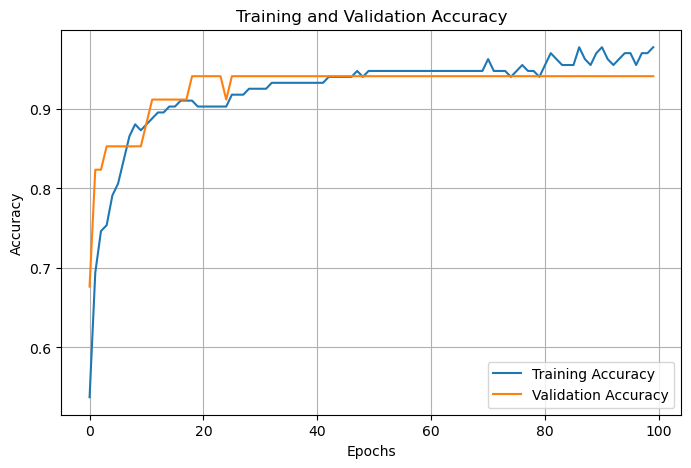

In [31]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

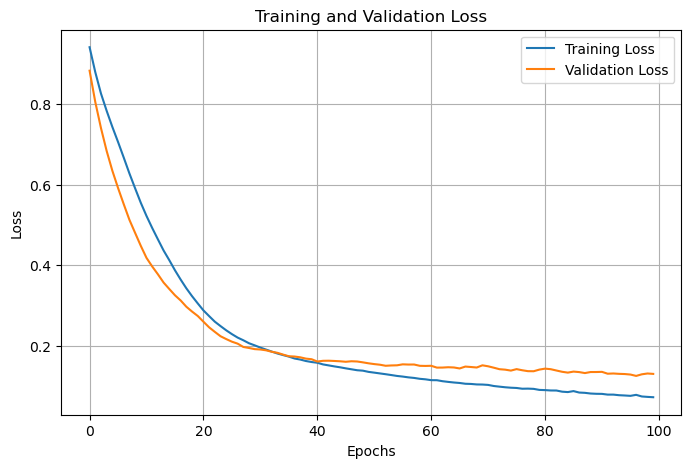

In [32]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show

In [33]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("Test Loss:",test_loss)
print("Test Accuracy:",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8571 - loss: 0.3651
Test Loss: 0.36510270833969116
Test Accuracy: 0.8571428656578064


In [34]:
y_prob = model.predict(X_test,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
[[9.8888397e-01 3.4779613e-03 7.6380530e-03]
 [2.4813304e-02 6.3756961e-05 9.7512293e-01]
 [6.7595780e-01 2.9651248e-01 2.7529640e-02]
 [6.0982991e-04 5.4842826e-07 9.9938965e-01]
 [2.8723959e-04 9.9970853e-01 4.2342490e-06]]


In [35]:
y_pred = np.argmax(y_prob,axis=1)
print("Predicted Encoded Classes:")
print(y_pred[:10])

Predicted Encoded Classes:
[0 2 0 2 1 2 1 1 1 1]


In [36]:
y_pred_original = y_pred+1
y_test_original=y_test+1
print("Predicted Classes:")
print(y_pred_original[:10])

Predicted Classes:
[1 3 1 3 2 3 2 2 2 2]


In [37]:
comparison = pd.DataFrame({'Actual': y_test_original, 'Predicted': y_pred_original})
print(comparison.head(10))

     Actual  Predicted
2         1          1
167       3          3
137       2          1
175       3          3
130       2          2
141       3          3
114       2          2
51        1          2
84        2          2
110       2          2


In [38]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print("Accuracy:", accuracy)

Accuracy: 0.8571428571428571


In [39]:
precision = precision_score(y_test_original, y_pred_original, average='weighted')
print("Precision:", precision)

Precision: 0.8625


In [40]:
recall = recall_score(y_test_original, y_pred_original, average='weighted')
print("Recall:", recall)

Recall: 0.8571428571428571


In [41]:
f1_score = f1_score(y_test_original, y_pred_original, average='weighted')
print("F1 Score:", f1_score)

F1 Score: 0.8500000000000001


In [42]:
metric = classification_report(y_test_original, y_pred_original)
print("Classification Report:")
print(metric)

Classification Report:
              precision    recall  f1-score   support

           1       0.90      0.64      0.75        14
           2       0.81      0.93      0.87        14
           3       0.88      1.00      0.93        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42



In [43]:
cm = confusion_matrix(y_test_original, y_pred_original)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 9  3  2]
 [ 1 13  0]
 [ 0  0 14]]


<function matplotlib.pyplot.show(close=None, block=None)>

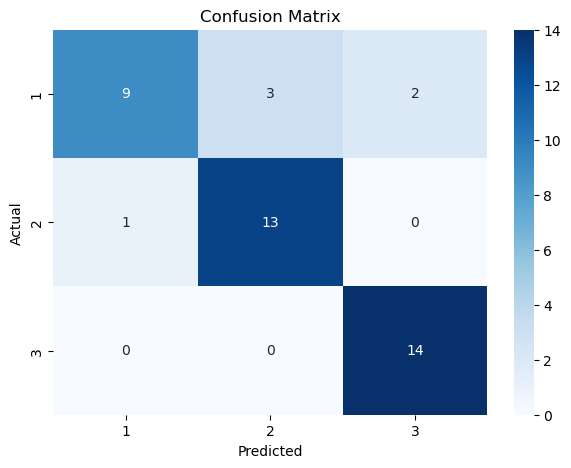

In [44]:
plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y_original.unique()),
    yticklabels=sorted(y_original.unique())
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show

--------------------------------------------------------------------------------